# Real VLMs: SmolVLM-256M, LLaVA-OneVision, Qwen2-VL

The mini-VLMs of notebook 08 are controlled but tiny. Here, the same protocol on VLMs trained by their authors:

| model | vision encoder (resolution) | language model |
|---|---|---|
| SmolVLM-256M (model of notebooks 01–07, splitting off) | SigLIP-B/16 (512) | SmolLM2-135M |
| LLaVA-OneVision-0.5B | SigLIP-SO400M (384) | Qwen2-0.5B |
| Qwen2-VL-2B | its own ViT (448) | Qwen2-1.5B |
| Qwen2-VL-2B at 224 px | same model, resolution of the mini-VLMs | |

Captions go through each model's own processor from 8-bit images; the attack's gradient goes through a differentiable copy of the preprocessing, checked against the processor. Two universal attacks: on the **encoder tokens** (as in notebook 01) and **end-to-end** on the clean caption likelihood.

Commands: `minivlm/run_real_vlm.sh <model>`, `run_endtoend.sh`, `run_single.sh` (per-image attack), `run_complete.sh` (seeds). Report: Parts VI and VII.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('minivlm'))   # run from smol_exp/, where notebooks 01-07 are
import numpy as np
import matplotlib.pyplot as plt
from nb_utils import *
use_style()
print('result files read from', RESULTS_DIR)

result files read from /home/kemnhou/Bureau/universal/smol_exp/minivlm/results


## 1. Overview

In [2]:
rows = []
for m in REAL:
    draws = [d for d in ['', ', draw 1', ', draw 2', ', draw 3', ', draw 4'] if has(m, 'random ±xi' + d)]
    noise = np.mean([inv2(m, 'random ±xi' + d)['rate'] for d in draws])
    seeds = [inv2(m, own(m, s))['rate'] for s in ['', 'seed 1', 'seed 2'] if has(m, own(m, s))]
    e2e = inv2(m, own(m, 'caption loss')) if has(m, own(m, 'caption loss')) else None
    rows.append([NAMES[m], pct(coco(m, 'clean', 'wrong'), False), '%.1f %% (%d draw%s)' % (noise, len(draws), 's' * (len(draws) > 1)),
                 pct(coco(m, own(m)), False) + ' / ' + pct(inv2(m, own(m)), False),
                 ' / '.join('%.1f' % s for s in seeds), pct(e2e) if e2e else 'not run (out of memory)'])
show_table(['model', 'clean, wrong (COCO)', 'random ±ξ, ImageNetV2', 'token v: COCO / ImageNetV2',
            'token v, ImageNetV2, seeds 0/1/2 (%)', 'end-to-end v, ImageNetV2'], rows, 'captions changed, ξ = 10/255')

**captions changed, ξ = 10/255**

| model | clean, wrong (COCO) | random ±ξ, ImageNetV2 | token v: COCO / ImageNetV2 | token v, ImageNetV2, seeds 0/1/2 (%) | end-to-end v, ImageNetV2 |
|---|---|---|---|---|---|
| SmolVLM-256M | 23.9 % | 4.4 % (5 draws) | 88.2 % / 91.2 % | 91.2 / 93.4 / 93.2 | 63.6 % (59.3–67.7) |
| LLaVA-OV-0.5B | 5.8 % | 2.2 % (1 draw) | 60.9 % / 70.2 % | 70.2 | not run (out of memory) |
| Qwen2-VL 448 | 1.6 % | 1.4 % (5 draws) | 2.2 % / 5.6 % | 5.6 / 14.8 / 13.4 | 27.8 % (24.1–31.9) |
| Qwen2-VL 224 | 4.7 % | 3.4 % (5 draws) | 10.7 % / 15.2 % | 15.2 / 21.4 / 16.4 | 23.8 % (20.3–27.7) |

SmolVLM-256M and LLaVA are clearly vulnerable, and their perturbed captions are false (high *wrong*). The perturbation of notebook 01 is reproduced here (report VI.1). Qwen2-VL looks much more robust under the token attack. The next sections show why that impression is wrong.

## 2. Qwen2-VL: the attack that almost concluded "robust"

A first end-to-end attack, with the step size used for the mini-VLMs (4/255), declared convergence after 23 epochs and changed only 7.8 % of the ImageNetV2 captions (report C.4; its captions are archived on the GPU machine, only its history is here). The same attack with a step eight times smaller:

ImageNetV2 captions changed with the 0.5/255 run: 27.8 % (24.1–31.9)


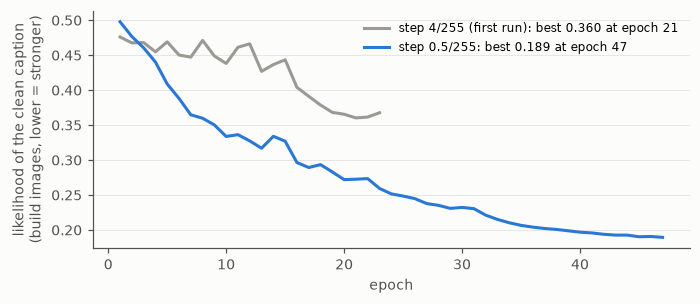

In [3]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for f, col, lab in [('old_lr4/uap_cap_xi10_history.json', GRAY, 'step 4/255 (first run)'),
                    ('uap_cap_xi10_history.json', BLUE, 'step 0.5/255')]:
    h = load('qwen2-vl-2b', f)
    ax.plot([r['epoch'] for r in h['history']], [r['build_score'] for r in h['history']], color=col, lw=2,
            label='%s: best %.3f at epoch %d' % (lab, h['best'], h['best_epoch']))
ax.set_xlabel('epoch'); ax.set_ylabel('likelihood of the clean caption\n(build images, lower = stronger)')
ax.legend(fontsize=8); plt.show()
print('ImageNetV2 captions changed with the 0.5/255 run:', pct(inv2('qwen2-vl-2b', own('qwen2-vl-2b', 'caption loss'))))

The well-optimised perturbation does more than change captions: it **injects a concept** into them.

In [4]:
import re
for m, pat, word in [('qwen2-vl-2b', 'mathemat|equation|formula', 'equations'),
                     ('qwen2-vl-2b-224', 'circuit|digital|futuristic|technolog', 'circuit / digital')]:
    rows = []
    for ds in ['coco', 'imagenetv2']:
        c = captions(m, ds)
        share = lambda caps: 100 * np.mean([bool(re.search(pat, s, re.I)) for s in caps])
        rows.append([ds, '%.1f %%' % share(c['clean']), '**%.1f %%**' % share(c[own(m, 'caption loss')])])
    show_table(['dataset', 'clean captions', 'under the end-to-end v'], rows,
               '%s: captions mentioning “%s”' % (NAMES[m], word))

c = captions('qwen2-vl-2b')
k = own('qwen2-vl-2b', 'caption loss')
shown = 0
for a, b in zip(c['clean'], c[k]):
    if re.search('equation', b, re.I) and len(a) < 110:
        print('clean:', a.strip()); print('  v  :', b.strip(), '\n'); shown += 1
    if shown == 4:
        break

clean: A blue jay perches on a branch amidst lush green foliage.
  v  : A blue jay perched on a tree branch with mathematical equations and symbols floating around it. 

clean: A bowl filled with green apples is placed on a reflective surface, with a wooden column behind it.
  v  : A man in a suit stands in front of a bowl filled with green apples, surrounded by mathematical equations and symbols. 

clean: The image features a Mexican flag waving in the wind against a clear blue sky.
  v  : The image features a Mexican flag waving in the wind, with mathematical equations and formulas floating around it, symbolizing the blend of traditional and modern aspects of Mexican culture and science. 

clean: A close-up of a meerkat with a curious expression, looking to the side.
  v  : The image features a meerkat surrounded by mathematical equations and symbols, creating a surreal and abstract visual. 



**Qwen2-VL 448: captions mentioning “equations”**

| dataset | clean captions | under the end-to-end v |
|---|---|---|
| coco | 0.0 % | **72.2 %** |
| imagenetv2 | 0.0 % | **79.6 %** |

**Qwen2-VL 224: captions mentioning “circuit / digital”**

| dataset | clean captions | under the end-to-end v |
|---|---|---|
| coco | 0.2 % | **51.2 %** |
| imagenetv2 | 1.0 % | **58.6 %** |

Qwen2-VL still names the subject, but the attacker controls part of **every** caption. Our main metric counts only captions whose overall meaning changes, so it strongly undercounts this attack (report VI.2, confidence A). **Concluding robustness needs an attack checked to have gone all the way** (report VI.3).

## 3. Three seeds of the token attack on Qwen2-VL 448

Same attack, three starting points. The share of changed captions is recomputed from the captions, then compared seed against seed on the same images (McNemar).

In [5]:
m = 'qwen2-vl-2b'
STYLE = 'glitch|abstract|surreal|pixelat|distort'
keys = {s or 'seed 0': own(m, s) for s in ['', 'seed 1', 'seed 2']}
tok = load(m, 'uap_xi10_tokens.json')['token_cos']
flags, rows = {}, []
for ds in ['imagenetv2', 'coco']:
    c = captions(m, ds)
    for s, k in keys.items():
        flags[ds, s] = changed_flags(c['clean'], c[k])
for s, k in keys.items():
    style = [100 * np.mean([bool(re.search(STYLE, x, re.I)) for x in captions(m, ds)[k]]) for ds in ['coco', 'imagenetv2']]
    rows.append([s, '%.3f' % tok[k], '%.1f %%' % (100 * flags['coco', s].mean()),
                 '%.1f %%' % (100 * flags['imagenetv2', s].mean()), '%.1f %% / %.1f %%' % tuple(style)])
show_table(['seed', 'token cosine (held-out)', 'changed, COCO', 'changed, ImageNetV2',
            '“glitch / abstract / surreal …” style, COCO / ImageNetV2'], rows, 'Qwen2-VL 448, token v')
rows = []
for a, b in [('seed 0', 'seed 1'), ('seed 0', 'seed 2'), ('seed 1', 'seed 2')]:
    for ds in ['imagenetv2', 'coco']:
        x, y, p = mcnemar(flags[ds, a], flags[ds, b])
        rows.append(['%s vs %s' % (a, b), ds, '%d vs %d' % (x, y), '%.1g' % p])
show_table(['pair', 'dataset', 'discordant pairs', 'McNemar p'], rows)

**Qwen2-VL 448, token v**

| seed | token cosine (held-out) | changed, COCO | changed, ImageNetV2 | “glitch / abstract / surreal …” style, COCO / ImageNetV2 |
|---|---|---|---|---|
| seed 0 | 0.878 | 2.2 % | 5.6 % | 0.4 % / 0.6 % |
| seed 1 | 0.872 | 8.4 % | 14.8 % | 52.9 % / 66.2 % |
| seed 2 | 0.826 | 7.2 % | 13.4 % | 26.8 % / 38.8 % |

| pair | dataset | discordant pairs | McNemar p |
|---|---|---|---|
| seed 0 vs seed 1 | imagenetv2 | 12 vs 58 | 2e-08 |
| seed 0 vs seed 1 | coco | 11 vs 73 | 2e-12 |
| seed 0 vs seed 2 | imagenetv2 | 8 vs 47 | 8e-08 |
| seed 0 vs seed 2 | coco | 11 vs 61 | 2e-09 |
| seed 1 vs seed 2 | imagenetv2 | 36 vs 29 | 0.5 |
| seed 1 vs seed 2 | coco | 55 vs 43 | 0.3 |

In [6]:
c = captions(m)
for s in ['seed 1', 'seed 2']:
    shown = 0
    for a, b in zip(c['clean'], c[keys[s]]):
        if re.search(STYLE + '|digital', b, re.I) and len(b) < 130:
            print('%s | clean: %s\n       |   v  : %s\n' % (s, a.strip(), b.strip())); shown += 1
        if shown == 2:
            break

seed 1 | clean: A blue jay perches on a branch amidst lush green foliage.
       |   v  : A vibrant, stylized image of a blue jay perched on a tree branch, with a futuristic, pixelated effect.

seed 1 | clean: Two fluffy, white dogs with long, curly fur stand side by side on a grassy field, with one dog wagging its tail.
       |   v  : Two adorable dogs stand side by side on a grassy field, with a glitch effect applied to the image.

seed 2 | clean: A blue jay perches on a branch amidst lush green foliage.
       |   v  : A blue jay perches on a branch amidst green foliage, with a digital glitch effect applied to the image.

seed 2 | clean: A close-up of a meerkat with a curious expression, looking to the side.
       |   v  : The image features a meerkat with a digital, abstract background.



**Seed 0 is the outlier.** Seeds 1 and 2 each differ significantly from seed 0 and not from each other, and both inject a "glitch / abstract / digital" style that seed 0 never produces. A single seed, as in notebooks 01–07, would have under-estimated the vulnerability by a factor of about 2.5. The optimised score does not predict any of this: seed 2 has the best token cosine but injects the style less often than seed 1 (report VI.7, confidence B).

## 4. Transfers across resolutions are confounded by resizing

Qwen 448 token v, downscaled to 224 px, on the SAME model at 224 px: 1.0 % (0.4–2.3) | noise: 3.4 % (2.1–5.4)


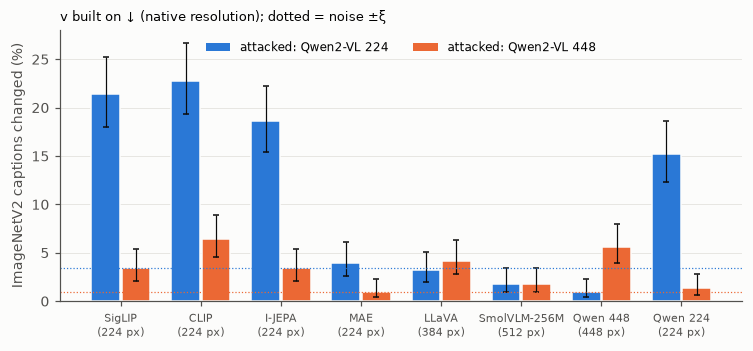

In [7]:
src = [('siglip', 224), ('clip', 224), ('ijepa', 224), ('mae', 224), ('llava-ov-0.5b', 384),
       ('smolvlm-256m', 512), ('qwen2-vl-2b', 448), ('qwen2-vl-2b-224', 224)]
fig, ax = plt.subplots(figsize=(8, 3.2))
for i, (s, res) in enumerate(src):
    for dx, tgt, col in [(-0.19, 'qwen2-vl-2b-224', BLUE), (0.19, 'qwen2-vl-2b', ORANGE)]:
        k = own(s) if s == tgt else 'universal v (%s), transfer' % s
        if has(tgt, k):
            bars(ax, [i + dx], [inv2(tgt, k)], col, None, 0.36)
for tgt, col in [('qwen2-vl-2b-224', BLUE), ('qwen2-vl-2b', ORANGE)]:
    ax.axhline(inv2(tgt, 'random ±xi')['rate'], color=col, lw=0.8, ls=':')
    ax.bar(0, 0, 0, color=col, label='attacked: %s' % NAMES[tgt])
ax.set_xticks(range(len(src)), ['%s\n(%d px)' % (NAMES[s].replace('-OV-0.5B', '').replace('Qwen2-VL ', 'Qwen '), r)
                                for s, r in src], fontsize=7.5)
ax.set_ylabel('ImageNetV2 captions changed (%)'); ax.legend(fontsize=8, ncol=2, loc='upper center')
ax.set_title('v built on ↓ (native resolution); dotted = noise ±ξ', fontsize=8.5, loc='left')
plt.show()
r = inv2('qwen2-vl-2b-224', 'universal v (qwen2-vl-2b), transfer')
print('Qwen 448 token v, downscaled to 224 px, on the SAME model at 224 px:', pct(r),
      '| noise:', pct(inv2('qwen2-vl-2b-224', 'random ±xi')))

A model's own perturbation, resized, falls to the noise level **on that same model**. Every transfer between models of different resolutions is therefore dominated by resizing, and says nothing about transferability. Only v built at 224 px fool Qwen at 224 px (report VI.5, confidence A).

## 5. Universal versus per-image perturbations

On 40 images, a perturbation optimised **for each image** (100 steps, likelihood of the clean caption), at three budgets, against the best universal v of each model.

| model | per image 2/255 | per image 4/255 | per image 10/255 | best universal v, 10/255 |
|---|---|---|---|---|
| SmolVLM-256M | 85.0 % | 87.5 % | 92.5 % | 91.2 % |
| LLaVA-OV-0.5B | 47.5 % | 60.0 % | 77.5 % | 70.2 % |
| Qwen2-VL 448 | 37.5 % | 62.5 % | 72.5 % | 27.8 % |
| Qwen2-VL 224 | 45.0 % | 65.0 % | 90.0 % | 23.8 % |

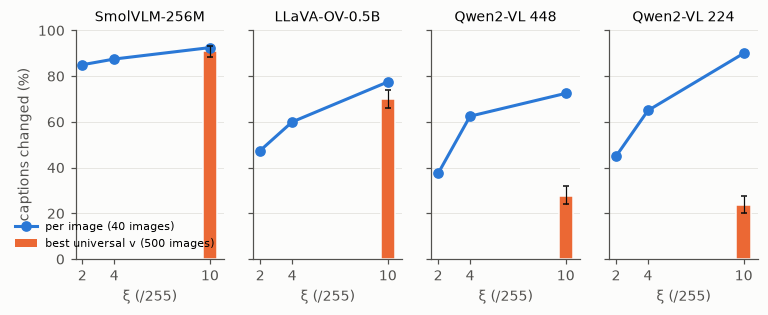

In [8]:
BEST = {'smolvlm-256m': own('smolvlm-256m'), 'llava-ov-0.5b': own('llava-ov-0.5b'),
        'qwen2-vl-2b': own('qwen2-vl-2b', 'caption loss'), 'qwen2-vl-2b-224': own('qwen2-vl-2b-224', 'caption loss')}
rows = []
fig, axes = plt.subplots(1, 4, figsize=(8, 2.7), sharey=True)
for ax, m in zip(axes, REAL):
    r = load(m, 'single_image.json')['results']
    xs = [float(k.split()[1].split('/')[0]) for k in r]
    ys = [v['changed@0.5']['rate'] for v in r.values()]
    ax.plot(xs, ys, color=BLUE, lw=2, marker='o', label='per image (40 images)')
    bars(ax, [10], [inv2(m, BEST[m])], ORANGE, 'best universal v (500 images)', 0.9)
    ax.set_xticks([2, 4, 10]); ax.set_xlabel('ξ (/255)'); ax.set_title(NAMES[m], fontsize=9); ax.set_ylim(0, 100)
    rows.append([NAMES[m]] + ['%.1f %%' % y for y in ys] + [pct(inv2(m, BEST[m]), False)])
axes[0].set_ylabel('captions changed (%)'); axes[0].legend(fontsize=7, loc='lower right')
plt.show()
show_table(['model', 'per image 2/255', 'per image 4/255', 'per image 10/255', 'best universal v, 10/255'], rows)

Every model can be fooled image by image with a small budget. On Qwen2-VL the gap with the universal v is large in "changed", but this is not real robustness: its universal v injects a concept rather than replacing the caption, which the metric does not count (report VII.1, confidence B). With 40 images the intervals are about ±15 points.

## Takeaways

| conf. | finding |
|---|---|
| A | None of the real VLMs tested is robust to a universal perturbation run to convergence. |
| A | On Qwen2-VL the perturbation injects a concept ("mathematical equations") into most captions; "changed" undercounts it. |
| A | A first, poorly optimised attack nearly concluded "Qwen2-VL is robust". |
| A | Transfers between different resolutions are confounded with resizing. |
| B | On Qwen2-VL 448 the attack seed changes the result and the mode of attack; seed 0 was the outlier. |

**Missing.** End-to-end attack and seeds on LLaVA (ran out of GPU memory; `./run_complete.sh llava`).